In [42]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path
import matplotlib.patches as patches
import sys
sys.path.append("/Genomics/argo/users/yz8667/src")
import all_function_py3
import ipynbname
pd.set_option('display.max_columns', None)

# General preparation (run this before running any code)

In [2]:
def quadratic_bezier_curves(t, p0, p1, p2):
	'''
	p0: e.g. (0, 0)
	p1: e.g. (1, 1)
	p2: e.g. (2, 0)
	'''
	x = (1 - t) * ((1 - t) * p0[0] + t * p1[0]) + t * ((1 - t) * p1[0] + t * p2[0])
	y = (1 - t) * ((1 - t) * p0[1] + t * p1[1]) + t * ((1 - t) * p1[1] + t * p2[1])
	return (x, y)

def shell_layout_ASD(G, cluster_marker, ax, x_range, y_range, output = None, ordered_genes = None, interval_ratio = 1, \
	edge_magnifier = 1, fontsize = 16, benchmarkcat2genes = {}, benchmarkcat2color = {}, \
	center = (0,0), marker_zoom = 0.05, title = None, title_pos = "top", title_fontsize = 50):
	'''
	G: a module whose nodes have attribute **secondary**, and whose edges have attribute **weight**
	cluster_marker: the image representing a cluster
	benchmarkcat2genes: a dictionary mapping SFARI categories to corresponding genes in that category
    benchmark2color: a dictionary mapping SFARI categories to corresponding colors
	interval_ratio: 1 means one node could be placed between two neighboring nodes.
	title_pos: 1. top; 2. bottom
	'''
	# get maxiumum edge weight
	gene2label = {}
	for i, x in enumerate(ordered_genes):
		gene2label[x] = (0.25 + (i + 0.5) / len(ordered_genes)) % 1

	# plot nodes
	perimeter = (1 + interval_ratio) * len(ordered_genes)
	shell_radius = perimeter / (2 * np.pi)
	r_text = shell_radius + 0.6 + fontsize / 70
	self_loop_weight = []
	for u,v,info in G.edges(data = True):
		if u == v:
			self_loop_weight.append(info["weight"])
	if len(self_loop_weight) > 0:
		r_text = r_text + 0.6 + max(self_loop_weight) * edge_magnifier / 50
	ax.set_aspect(1)
	for gene in gene2label:
		node_color = "black"
		for benchmarkcat, genes in benchmarkcat2genes.items():
			if gene in genes:
				node_color = benchmarkcat2color[benchmarkcat]
				break
		angle = gene2label[gene]
		x = center[0] + shell_radius * np.cos(angle * 2 * np.pi)
		y = center[1] + shell_radius * np.sin(angle * 2 * np.pi)
		circle = plt.Circle((x, y), 0.5, color = node_color)
		ax.add_artist(circle)
		if angle < 0.75 and angle > 0.25:
			rotation = angle * 360 + 90 + 180
		else:
			rotation = angle * 360 - 90
		plt.text(center[0] + r_text * np.cos(angle * 2 * np.pi), center[1] + r_text * np.sin(angle * 2 * np.pi), gene, horizontalalignment = "center", \
			verticalalignment = "center", rotation = rotation, fontsize = fontsize, color = "#252525", fontweight = "light")
	
	# plot lines
	codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3]
	for x,y,info in G.edges(data = True):
		angle1 = gene2label[x]
		angle2 = gene2label[y]
		angle = (angle1 + angle2) / 2
		if x != y:
			smaller, larger = sorted([ordered_genes.index(x), ordered_genes.index(y)])
			if larger - smaller > 0.5 * len(ordered_genes):
				diff = smaller + len(ordered_genes) - larger
			else:
				diff = larger - smaller
			r_marker = 0.5 / diff * shell_radius
			if abs(angle1 - angle2) > 0.5:
				angle = angle - 0.5
			x_marker = center[0] + r_marker * np.cos(angle * 2 * np.pi)
			y_marker = center[1] + r_marker * np.sin(angle * 2 * np.pi)
			verts = [(center[0] + shell_radius * np.cos(angle1 * 2 * np.pi), center[1] + shell_radius * np.sin(angle1 * 2 * np.pi)), # P0
					 (x_marker, y_marker),  # P1
					 (center[0] + shell_radius * np.cos(angle2 * 2 * np.pi), center[1] + shell_radius * np.sin(angle2 * 2 * np.pi))]  # P2
			path = Path(verts, codes)
			patch = patches.PathPatch(path, facecolor = 'none', lw = info["weight"] * edge_magnifier, edgecolor = "#252525", zorder = 0)
			ax.add_patch(patch)
			if info["weight"] > 1:
				x_vertex, y_vertex = quadratic_bezier_curves(0.5, verts[0], verts[1], verts[2])
				all_function_py3.display_image(cluster_marker, ax, x_vertex, y_vertex, zoom = marker_zoom)
		else:
			circle = plt.Circle((center[0] + (shell_radius + 0.65) * np.cos(angle1 * 2 * np.pi), \
				center[1] + (shell_radius + 0.65) * np.sin(angle1 * 2 * np.pi)), 0.35, \
				edgecolor = "#252525", linewidth = info["weight"] * edge_magnifier, zorder = 0, fill = False)
			ax.add_artist(circle)
			if info["weight"] > 1:
				all_function_py3.display_image(cluster_marker, ax, center[0] + (shell_radius + 0.8) * np.cos(angle1 * 2 * np.pi), \
					center[1] + (shell_radius + 0.8) * np.sin(angle1 * 2 * np.pi), zoom = marker_zoom)

	if title != None:
		if title_pos == "top":
			y_title = center[1] + r_text + fontsize / 70 + 0.3
			va = "bottom"
		else:
			y_title = center[1] - r_text - 2 * fontsize / 70 - 0.3
			va = "top"
		plt.text(center[0], y_title, title, horizontalalignment = "center", verticalalignment = va, fontsize = title_fontsize, color = "#252525", \
			fontweight = "normal")

	ax.set_xlim(x_range[0], x_range[1])
	ax.set_ylim(y_range[0], y_range[1])
	plt.axis('off')
	if output != None:
		plt.savefig(output, transparent=True, facecolor='none', bbox_inches = "tight")
	return ax

In [ ]:
folder_path = str(ipynbname.path().parent) + "/../"
print(folder_path)

In [35]:
tada_output_path = f"{folder_path}/data/TADA/output/InhAll_DNVAll/"
netflow3d_output_path = f"{folder_path}/data/NetFlow3D/output/"
analysis_path = f"{folder_path}/data/analysis/"
figure_path = f"{folder_path}/figures/fig5/"

In [37]:
# load canonical UniProts
fasta_dict = {}
with open(f"{folder_path}/src/NetFlow3D/metadata/UP000005640_9606.fasta") as f:
    header = None
    seq_chunks = []

    for line in f:
        line = line.strip()
        if line.startswith(">"):
            if header is not None:
                fasta_dict[header] = "".join(seq_chunks)

            # parse header: >tr|A0A075B6V1|A0A075B6V1_HUMAN ...
            parts = line[1:].split("|")
            header = parts[1]
            seq_chunks = []
        else:
            seq_chunks.append(line)

    # last sequence
    if header is not None:
        fasta_dict[header] = "".join(seq_chunks)
len(fasta_dict)

20596

In [28]:
# load id mapping file
df_idmap = pd.read_csv(f"{folder_path}/src/NetFlow3D/metadata/HUMAN_9606_idmapping.dat.gz", sep="\t", header=None, names=["UniProt", "ID_type", "ID"])
df_idmap = df_idmap[df_idmap["ID_type"] == "Gene_Name"]
df_idmap["UniProt"] = df_idmap["UniProt"].apply(lambda x: x.split("-")[0])
df_idmap["ID"] = df_idmap["ID"].apply(lambda x: x.split(".")[0])
df_idmap_slim = df_idmap[df_idmap["UniProt"].isin(fasta_dict.keys())]
display(df_idmap)
display(df_idmap_slim)

,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
6198707,A0A678ZI47,Gene_Name,HLA-DRB1
6198717,A0A678ZTH6,Gene_Name,HLA-DQB1
6198728,A0A1C8DU67,Gene_Name,HLA-DRB1
6198740,A0A1D8MAN8,Gene_Name,HLA-A


,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
5924608,A0A0J9YVS3,Gene_Name,IGHJ4
6024285,A0A0J9YW14,Gene_Name,IGHJ3
6026795,A0A0G2JNF4,Gene_Name,KIR2DP1
6062812,A0A140TA62,Gene_Name,LOC100653049


# Visualization

## load assets

In [6]:
cluster_marker = f"{folder_path}/assets/cluster.png"

## load NetFlow3D results

In [7]:
dr = f"{folder_path}/data/NetFlow3D/output/"
coding_cohort_tag = "coding_FuScaled_ASC+SSC"
sample_tag = "Combined_Simple"
method_tag = "ScaleByLOEUF"
disrupted_ppi_tag = "Interface_DN"
file_prefix = f"InhAll_DNVAll_TADA_{coding_cohort_tag}_rounded_{sample_tag}_Roulette_MR_{method_tag}_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"


In [8]:
G = nx.read_graphml(dr + file_prefix + "/initial_state.graphml.gz")

In [9]:
df = pd.read_csv(dr + file_prefix + "_subnetworks.txt", sep="\t")
df

,Subnetwork_genes,Subnetwork_size
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
...,...,...
6356,Q9Y2H2,1
6357,Q9Y3E5,1
6358,Q9Y5W7,1
6359,Q9Y6X9,1


In [10]:
df_sig = df[df["Subnetwork_size"] > 5]
print(df_sig.shape[0])
df_sig

10


,Subnetwork_genes,Subnetwork_size
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
5,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3,Q6WCQ1",7
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6
7,"P78362,Q05519,Q8WVK2,Q8WXA9,Q9BSF8,Q9UKV3",6
8,"O75899,P09471,P21554,P62873,P63096,Q9UGC6",6
9,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6


In [11]:
df_sig["subnetwork_id"] = (df_sig.groupby("Subnetwork_size").cumcount() + 1)
df_sig["subnetwork_id"] = ("size" + df_sig["Subnetwork_size"].astype(str) + "_" + df_sig["subnetwork_id"].astype(str))
df_sig

/tmp/ipykernel_166918/2827330563.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sig["subnetwork_id"] = (df_sig.groupby("Subnetwork_size").cumcount() + 1)
/tmp/ipykernel_166918/2827330563.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sig["subnetwork_id"] = ("size" + df_sig["Subnetwork_size"].astype(str) + "_" + df_sig["subnetwork_id"].astype(str))


,Subnetwork_genes,Subnetwork_size,subnetwork_id
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33,size33_1
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16,size16_1
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10,size10_1
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8,size8_1
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7,size7_1
5,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3,Q6WCQ1",7,size7_2
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6,size6_1
7,"P78362,Q05519,Q8WVK2,Q8WXA9,Q9BSF8,Q9UKV3",6,size6_2
8,"O75899,P09471,P21554,P62873,P63096,Q9UGC6",6,size6_3
9,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6,size6_4


In [103]:
dr = f"{folder_path}/data/analysis/InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5/"
df = pd.read_csv(dr + "NetFlow3D_vs_random_jaccard.txt", sep="\t")
df[df["Group"] == "NetFlow3D_Subnetwork"]

,Subnetwork_genes,GO_Pathway,Jaccard,Group,Overlapped_elements,Numerator,Denominator,Permutation_round
0,"RBBP5,AXL,MAP6,LBH,TCF4,NR3C2,THRB,NCOA1,RORB,...",Thyroid hormone mediated signaling pathway,0.081081,NetFlow3D_Subnetwork,"THRB,THRA,NCOA1",3,37,NaN
1,"NRXN1,DLG4,TIAM1,GRIN2B,GRIN2A,DLGAP1,NRXN2,KC...",Excitatory chemical synaptic transmission,0.142857,NetFlow3D_Subnetwork,"GRIN1,GRIN2B,GRIN2A",3,21,NaN
2,"RAPGEF4,SLC16A1,ZC3H11A,SPTBN2,TRIP12,SWAP70,A...",Dopaminergic neuron axon guidance,0.071429,NetFlow3D_Subnetwork,CELSR3,1,14,NaN
3,"BCL9,SORCS3,PCDH8,BTRC,ICE1,CTNNB1,CHPF,PYGO2",Beta catenin tcf complex assembly,0.085714,NetFlow3D_Subnetwork,"BCL9,PYGO2,CTNNB1",3,35,NaN
4,"BCAR1,VCL,SORBS1,NEDD9,SEMA6A,BIRC6,TLN1",Actin filament reorganization,0.142857,NetFlow3D_Subnetwork,"NEDD9,BCAR1",2,14,NaN
5,"SPOP,MPRIP,TP53BP1,PTEN,MEX3C,BRD3,MACROH2A1",Negative regulation of transcription by rna po...,0.090909,NetFlow3D_Subnetwork,MACROH2A1,1,11,NaN
6,"MAML3,PIM1,RAI1,ZZZ3,NDN,ZBTB1",Positive regulation of hematopoietic progenito...,0.100000,NetFlow3D_Subnetwork,ZBTB1,1,10,NaN
7,"SRPK2,ACIN1,SRSF11,BTBD10,SNRNP27,SREK1",Apoptotic chromosome condensation,0.100000,NetFlow3D_Subnetwork,ACIN1,1,10,NaN
8,"GABBR2,CNR1,RGS17,GNAI1,GNAO1,GNB1",Negative regulation of fatty acid beta oxidation,0.100000,NetFlow3D_Subnetwork,CNR1,1,10,NaN
9,"ASH1L,MRTFB,KDM2A,CXXC5,ZBTB11,SMAD7",Negative regulation of transcription by compet...,0.142857,NetFlow3D_Subnetwork,"SMAD7,KDM2A",2,14,NaN


In [106]:
df[df["Group"] == "NetFlow3D_Subnetwork"]["GO_Pathway"].tolist()

['Thyroid hormone mediated signaling pathway',
 'Excitatory chemical synaptic transmission',
 'Dopaminergic neuron axon guidance',
 'Beta catenin tcf complex assembly',
 'Actin filament reorganization',
 'Negative regulation of transcription by rna polymerase i',
 'Positive regulation of hematopoietic progenitor cell differentiation',
 'Apoptotic chromosome condensation',
 'Negative regulation of fatty acid beta oxidation',
 'Negative regulation of transcription by competitive promoter binding']

## highlight SFARI genes

### parse SFARI genes

In [72]:
dr = f"{folder_path}/ref/SFARI_GeneList/"
df_sfari = pd.read_csv(dr + "SFARI-Gene_genes_03-22-2026release_03-23-2026export.csv")
df_sfari

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
0,9,ABAT,4-aminobutyrate aminotransferase,ENSG00000183044,16,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,9
1,9,ABCA10,"ATP-binding cassette, sub-family A (ABC1), mem...",ENSG00000154263,17,Rare Single Gene Mutation,2.0,0,NaN,4
2,9,ABCA13,ATP binding cassette subfamily A member 13,ENSG00000179869,7,"Rare Single Gene Mutation, Functional",2.0,0,NaN,16
3,9,ABCA2,ATP binding cassette subfamily A member 2,ENSG00000107331,9,Rare Single Gene Mutation,3.0,0,NaN,8
4,9,ABCA7,"ATP-binding cassette, sub-family A (ABC1), mem...",ENSG00000064687,19,Rare Single Gene Mutation,2.0,0,NaN,7
...,...,...,...,...,...,...,...,...,...,...
1262,9,ZNF804A,Zinc finger protein 804A,ENSG00000170396,2,"Rare Single Gene Mutation, Genetic Association...",2.0,0,NaN,16
1263,9,ZNF827,Zinc finger protein 827,ENSG00000151612,4,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,4
1264,9,ZNF865,zinc finger protein 865,ENSG00000261221,19,"Rare Single Gene Mutation, Syndromic",1.0,0,NaN,5
1265,9,ZSWIM6,zinc finger SWIM-type containing 6,ENSG00000130449,5,"Rare Single Gene Mutation, Syndromic, Genetic ...",NaN,1,NaN,8


In [73]:
df_sfari["gene-score"].unique()

array([ 2.,  3.,  1., nan])

In [74]:
df_sfari["syndromic"].unique()

array([0, 1])

In [75]:
df_sfari[df_sfari["syndromic"] == 1]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
10,9,ACTB,actin beta,ENSG00000075624,7,"Rare Single Gene Mutation, Syndromic",1.0,1,1.0,12
11,9,ACTL6B,actin like 6B,ENSG00000077080,7,"Rare Single Gene Mutation, Syndromic, Functional",NaN,1,NaN,16
13,9,ACY1,aminoacylase 1,ENSG00000243989,3,"Rare Single Gene Mutation, Syndromic",NaN,1,NaN,13
19,9,ADGRL1,adhesion G protein-coupled receptor L1,ENSG00000072071,19,"Rare Single Gene Mutation, Syndromic",3.0,1,NaN,5
21,9,ADNP,Activity-dependent neuroprotector homeobox,ENSG00000101126,20,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,41.5,100
...,...,...,...,...,...,...,...,...,...,...
1244,9,ZMYM3,zinc finger MYM-type containing 3,ENSG00000147130,X,"Rare Single Gene Mutation, Syndromic, Genetic ...",NaN,1,NaN,9
1246,9,ZMYND8,zinc finger MYND-type containing 8,ENSG00000101040,20,"Rare Single Gene Mutation, Syndromic",1.0,1,4.5,9
1248,9,ZNF292,zinc finger protein 292,ENSG00000188994,6,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,NaN,16
1251,9,ZNF462,Zinc finger protein 462,ENSG00000148143,9,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,10.6,20


In [76]:
df_sfari[df_sfari["gene-score"] == 1]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
5,9,ABCE1,ATP binding cassette subfamily E member 1,ENSG00000164163,4,Rare Single Gene Mutation,1.0,0,1.40,5
10,9,ACTB,actin beta,ENSG00000075624,7,"Rare Single Gene Mutation, Syndromic",1.0,1,1.00,12
21,9,ADNP,Activity-dependent neuroprotector homeobox,ENSG00000101126,20,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,41.50,100
23,9,ADSL,adenylosuccinate lyase,ENSG00000239900,22,"Rare Single Gene Mutation, Syndromic",1.0,1,0.35,9
25,9,AFF2,"AF4/FMR2 family, member 2",ENSG00000155966,X,"Rare Single Gene Mutation, Syndromic",1.0,0,8.70,25
...,...,...,...,...,...,...,...,...,...,...
1229,9,ZBTB21,zinc finger and BTB domain containing 21,ENSG00000173276,21,Rare Single Gene Mutation,1.0,0,NaN,4
1246,9,ZMYND8,zinc finger MYND-type containing 8,ENSG00000101040,20,"Rare Single Gene Mutation, Syndromic",1.0,1,4.50,9
1248,9,ZNF292,zinc finger protein 292,ENSG00000188994,6,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,NaN,16
1251,9,ZNF462,Zinc finger protein 462,ENSG00000148143,9,"Rare Single Gene Mutation, Syndromic, Functional",1.0,1,10.60,20


In [77]:
df_sfari[df_sfari["gene-score"] == 2]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
0,9,ABAT,4-aminobutyrate aminotransferase,ENSG00000183044,16,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,9
1,9,ABCA10,"ATP-binding cassette, sub-family A (ABC1), mem...",ENSG00000154263,17,Rare Single Gene Mutation,2.0,0,NaN,4
2,9,ABCA13,ATP binding cassette subfamily A member 13,ENSG00000179869,7,"Rare Single Gene Mutation, Functional",2.0,0,NaN,16
4,9,ABCA7,"ATP-binding cassette, sub-family A (ABC1), mem...",ENSG00000064687,19,Rare Single Gene Mutation,2.0,0,NaN,7
7,9,ACAP2,"ArfGAP with coiled-coil, ankyrin repeat and PH...",ENSG00000114331,3,"Rare Single Gene Mutation, Functional",2.0,0,NaN,5
...,...,...,...,...,...,...,...,...,...,...
1260,9,ZNF713,Zinc finger protein 713,ENSG00000178665,7,Rare Single Gene Mutation,2.0,0,NaN,3
1261,9,ZNF774,Zinc finger protein 774,ENSG00000196391,15,Rare Single Gene Mutation,2.0,0,NaN,4
1262,9,ZNF804A,Zinc finger protein 804A,ENSG00000170396,2,"Rare Single Gene Mutation, Genetic Association...",2.0,0,NaN,16
1263,9,ZNF827,Zinc finger protein 827,ENSG00000151612,4,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,4


In [78]:
df_sfari[df_sfari["gene-score"] == 3]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
3,9,ABCA2,ATP binding cassette subfamily A member 2,ENSG00000107331,9,Rare Single Gene Mutation,3.0,0,NaN,8
6,9,ABL2,"ABL proto-oncogene 2, non-receptor tyrosine ki...",ENSG00000143322,1,"Rare Single Gene Mutation, Functional",3.0,0,NaN,10
15,9,ADCY1,adenylate cyclase 1,ENSG00000164742,7,Rare Single Gene Mutation,3.0,0,NaN,4
18,9,ADGRB1,adhesion G protein-coupled receptor B1,ENSG00000181790,8,"Rare Single Gene Mutation, Functional",3.0,0,NaN,11
19,9,ADGRL1,adhesion G protein-coupled receptor L1,ENSG00000072071,19,"Rare Single Gene Mutation, Syndromic",3.0,1,NaN,5
...,...,...,...,...,...,...,...,...,...,...
1239,9,ZFX,zinc finger protein X-linked,ENSG00000005889,X,"Rare Single Gene Mutation, Syndromic",3.0,1,NaN,5
1241,9,ZFYVE9,zinc finger FYVE-type containing 9,ENSG00000157077,1,"Rare Single Gene Mutation, Functional",3.0,0,NaN,6
1253,9,ZNF532,zinc finger protein 532,ENSG00000074657,18,Rare Single Gene Mutation,3.0,0,NaN,4
1254,9,ZNF536,zinc finger protein 536,ENSG00000198597,19,"Rare Single Gene Mutation, Genetic Association...",3.0,0,NaN,11


In [79]:
312 + 244 + 708 + 221

1485

In [80]:
benchmarkcat2genes = {"Category S": df_sfari[df_sfari["syndromic"] == 1]["gene-symbol"].tolist(), \
                     "Category 1": df_sfari[df_sfari["gene-score"] == 1]["gene-symbol"].tolist(), \
                     "Category 2": df_sfari[df_sfari["gene-score"] == 2]["gene-symbol"].tolist(), \
                     "Category 3": df_sfari[df_sfari["gene-score"] == 3]["gene-symbol"].tolist(), \
                    }

In [81]:
for benchmarkcat,genes in benchmarkcat2genes.items():
    print(benchmarkcat, len(genes))

Category S 312
Category 1 244
Category 2 708
Category 3 221


In [82]:
benchmarkcat2color = {"Category S": "#dc2641", \
                     "Category 1": "#f97632", \
                     "Category 2": "#fbb101", \
                     "Category 3": "#e8e327", \
                    }

### draw subnetworks

In [83]:
df_sig

,Subnetwork_genes,Subnetwork_size,subnetwork_id
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33,size33_1
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16,size16_1
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10,size10_1
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8,size8_1
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7,size7_1
5,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3,Q6WCQ1",7,size7_2
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6,size6_1
7,"P78362,Q05519,Q8WVK2,Q8WXA9,Q9BSF8,Q9UKV3",6,size6_2
8,"O75899,P09471,P21554,P62873,P63096,Q9UGC6",6,size6_3
9,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6,size6_4


In [84]:
for x in df_sig["Subnetwork_genes"]:
    prots = x.split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    print(G_sub.nodes())

['ID3', 'ATG9A', 'MAP6', 'MEN1', 'PROX1', 'RBBP5', 'BCL11A', 'EXOC2', 'NR3C2', 'NCOA6', 'THRA', 'TCF4', 'NCOA1', 'THRB', 'RANBP9', 'LBH', 'GAS6', 'RMND5A', 'NR2F1', 'TCF3', 'RALA', 'KMT2C', 'RORB', 'GID8', 'CREBBP', 'MKLN1', 'SOGA1', 'FOXO1', 'MPPED2', 'SRCAP', 'AXL', 'NR2F6', 'KMT2A']
['KCNA3', 'GRIN1', 'DLG2', 'DLG4', 'NRXN2', 'SIPA1L1', 'GRIN2B', 'PDZD2', 'CAMK2A', 'SEMA4C', 'MACF1', 'LRRTM2', 'TIAM1', 'NRXN1', 'GRIN2A', 'DLGAP1']
['SLC16A1', 'CELSR3', 'RAPGEF4', 'ZC3H11A', 'SPTBN4', 'SPTBN2', 'TRIP12', 'ACTR1A', 'SWAP70', 'RAP1A']
['CHPF', 'PCDH8', 'PYGO2', 'SORCS3', 'BCL9', 'BTRC', 'ICE1', 'CTNNB1']
['BIRC6', 'SORBS1', 'NEDD9', 'BCAR1', 'TLN1', 'SEMA6A', 'VCL']
['MEX3C', 'SPOP', 'TP53BP1', 'BRD3', 'MPRIP', 'MACROH2A1', 'PTEN']
['PIM1', 'ZBTB1', 'NDN', 'MAML3', 'RAI1', 'ZZZ3']
['SRSF11', 'SRPK2', 'ACIN1', 'SNRNP27', 'SREK1', 'BTBD10']
['GABBR2', 'CNR1', 'GNAO1', 'RGS17', 'GNB1', 'GNAI1']
['MRTFB', 'KDM2A', 'ZBTB11', 'ASH1L', 'SMAD7', 'CXXC5']


In [85]:
module2ordered_genes = {
    "size33_1": ['THRB', 'RMND5A', 'GID8', 'RALA', 'EXOC2', 'RANBP9', 'MKLN1', 'AXL', 'GAS6', 'NCOA6', 'THRA', 'SOGA1', 'RORB', 'MAP6', 'MPPED2', 'NR2F6', 'BCL11A', 'NR2F1', 'FOXO1', 'TCF3', 'ID3', 'TCF4', 'ATG9A', 'SRCAP', 'CREBBP', 'KMT2A', 'KMT2C', 'RBBP5', 'MEN1', 'NCOA1', 'NR3C2', 'PROX1', 'LBH'], 
    "size16_1": ['CAMK2A', 'GRIN2B', 'KCNA3', 'SIPA1L1', 'NRXN1', 'LRRTM2', 'PDZD2', 'TIAM1', 'NRXN2', 'MACF1', 'SEMA4C', 'DLG2', 'DLGAP1', 'DLG4','GRIN1', 'GRIN2A'],
    "size10_1": ['RAPGEF4', 'SWAP70', 'SLC16A1', 'SPTBN4', 'TRIP12', 'CELSR3', 'SPTBN2', 'ACTR1A', 'RAP1A', 'ZC3H11A'],
    "size8_1": ['BTRC', 'ICE1', 'PCDH8', 'CHPF', 'BCL9', 'PYGO2', 'SORCS3', 'CTNNB1'],
    "size7_1": ['BIRC6', 'SEMA6A', 'SORBS1', 'VCL', 'TLN1', 'BCAR1', 'NEDD9'], 
    "size7_2": ['MPRIP', 'SPOP', 'BRD3', 'TP53BP1', 'MACROH2A1', 'MEX3C', 'PTEN'], 
    "size6_1": ['ZBTB1', 'NDN', 'PIM1', 'ZZZ3', 'MAML3', 'RAI1'],
    "size6_2": ['SREK1', 'SNRNP27', 'SRPK2', 'ACIN1', 'BTBD10', 'SRSF11'],
    "size6_3": ['GNAI1', 'RGS17', 'GNAO1', 'GNB1', 'CNR1', 'GABBR2'],
    "size6_4": ['CXXC5', 'ASH1L', 'KDM2A', 'MRTFB', 'ZBTB11', 'SMAD7']
}
module2title = {
    "size33_1": "Regulation of thyroid hormone\nreceptor signaling pathway", 
    "size16_1": "Excitatory synaptic\ntransmission\n", 
    "size10_1": "Dopaminergic neuron\naxon guidance\n", 
    "size8_1": "Wnt signaling pathway\n", 
    "size7_1": "Cell adhesion and\nmigration\n", 
    "size7_2": "p53 signaling\n", 
    "size6_1": "Transcriptional\nregulation\n",
    "size6_2": "RNA splicing\n",
    "size6_3": "G-protein signaling\n",
    "size6_4": "Transcription\nregulation\n",
}

size33_1
size16_1
size10_1
size8_1
size7_1
size7_2
size6_1
size6_2
size6_3
size6_4


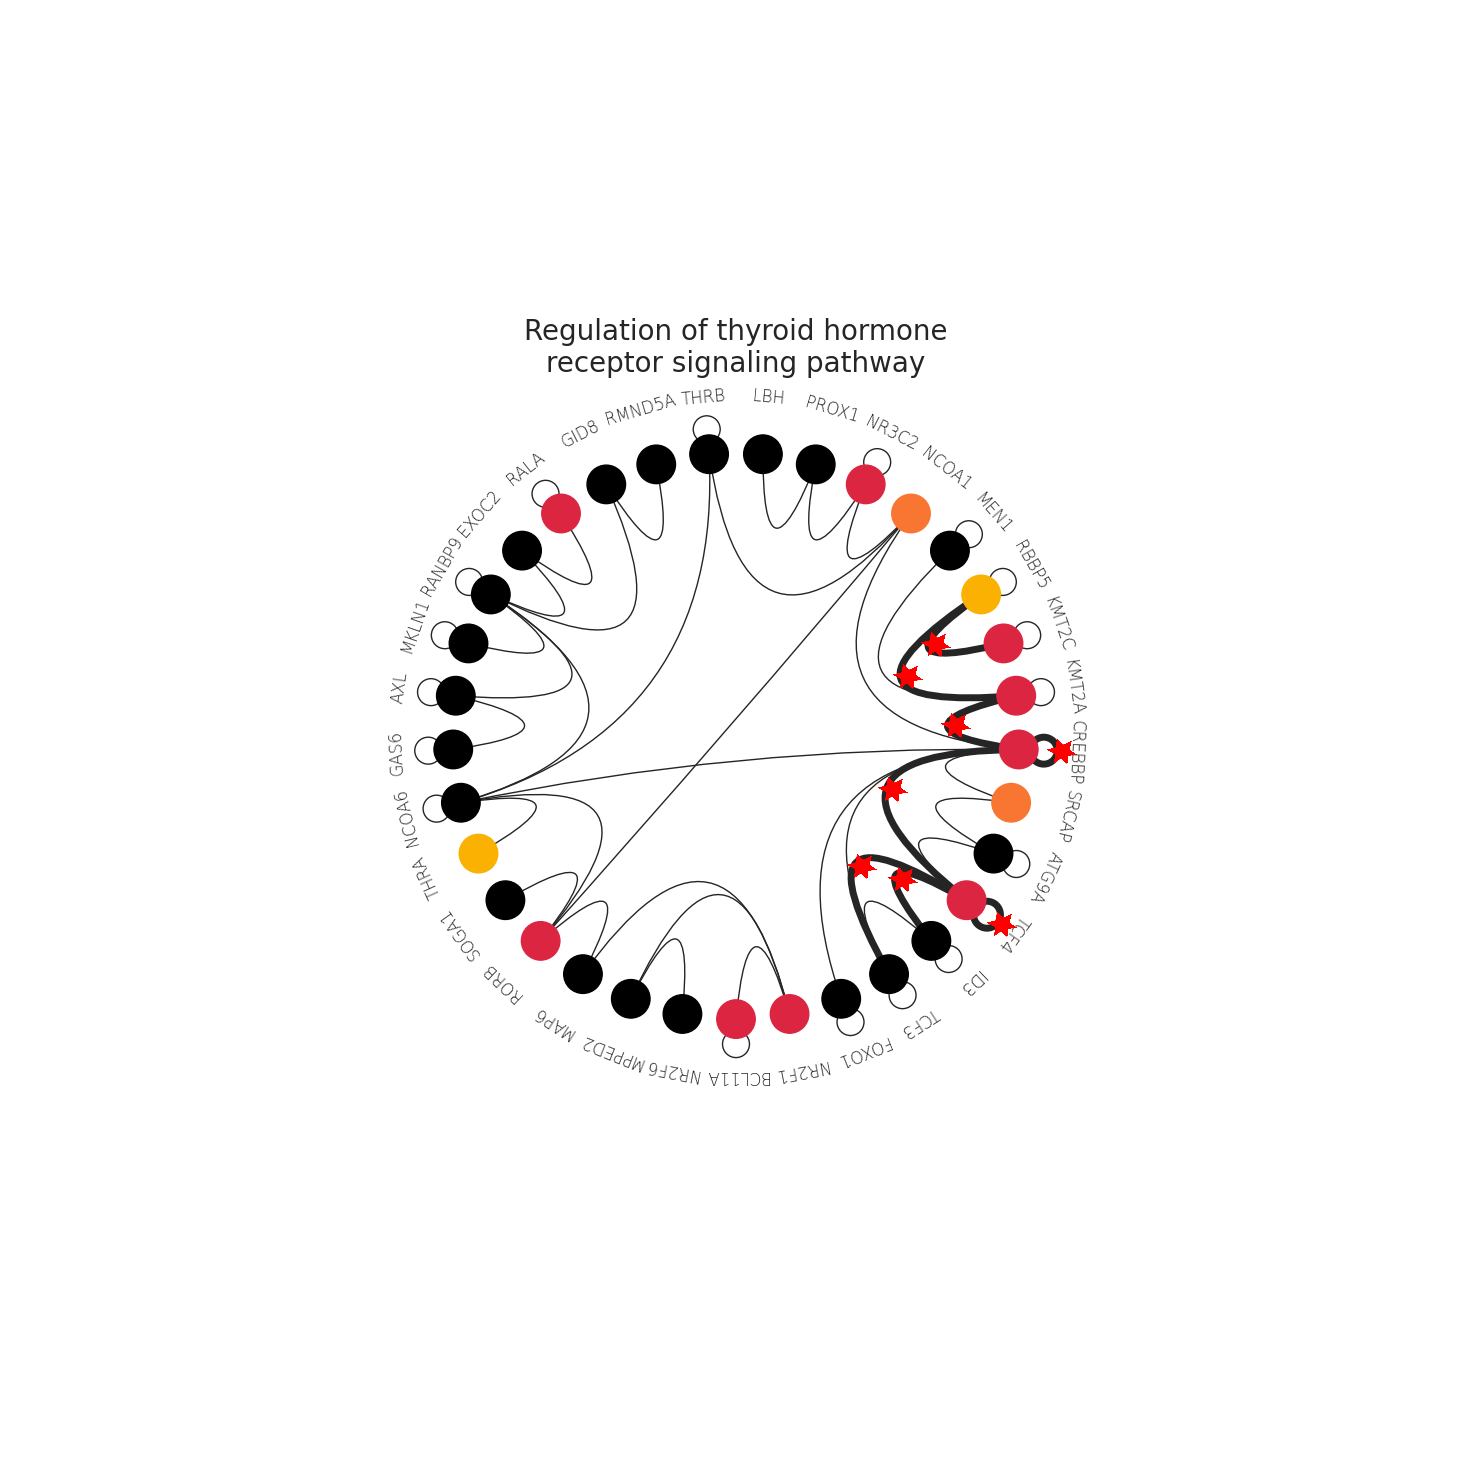

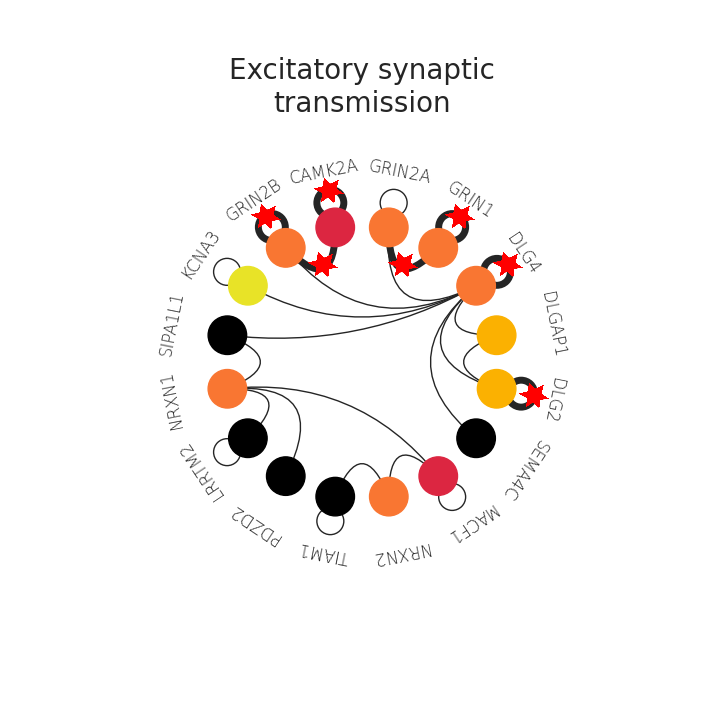

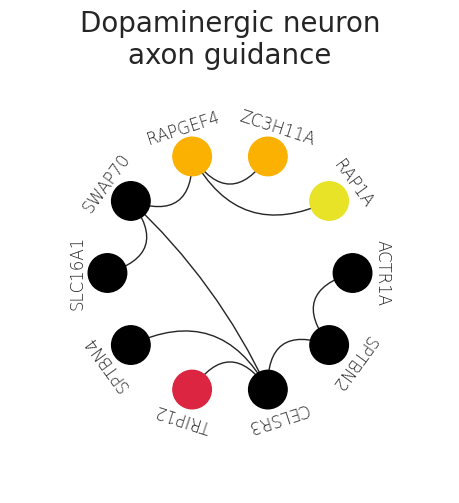

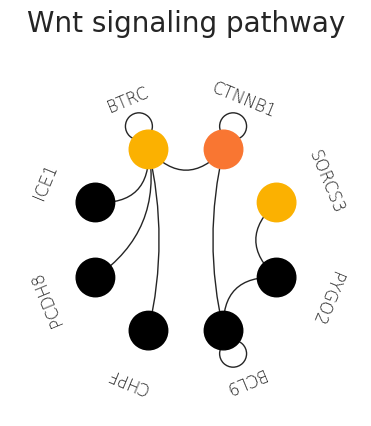

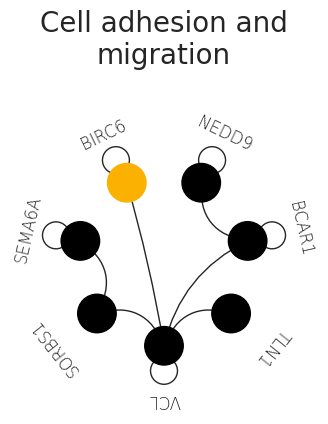

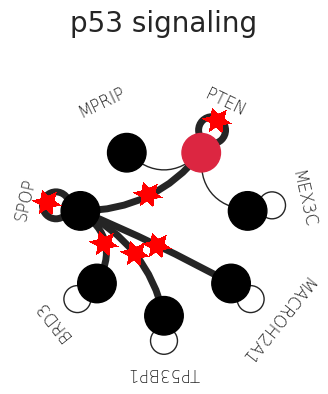

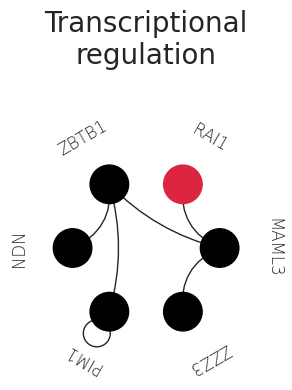

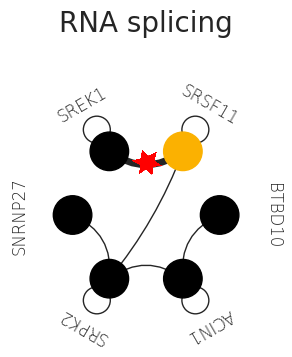

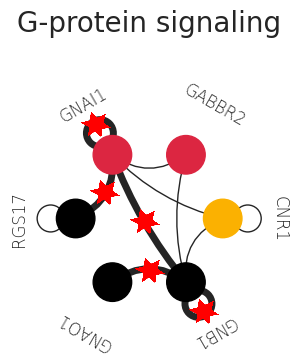

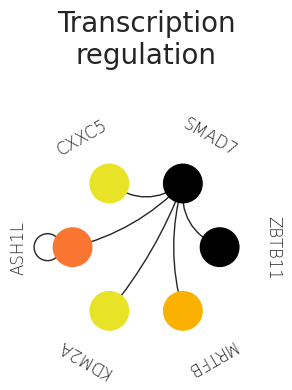

In [87]:
for x in df_sig.iterrows():
    subnetwork_id = x[1]["subnetwork_id"]
    title = module2title[subnetwork_id]
    print(subnetwork_id)
    prots = x[1]["Subnetwork_genes"].split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    b = len(set(G_sub.nodes()))

    figsize = 20 / 35 * len(set(G_sub.nodes()))
    figure, ax = plt.subplots(figsize = (figsize, figsize))
    x_range = (-figsize, figsize)
    y_range = (-figsize, figsize)
    try:
        ordered_genes = module2ordered_genes[subnetwork_id]
    except:
        ordered_genes = list(G_sub.nodes())
    if x[1]["Subnetwork_size"] > 15:
         interval_ratio = 0.4
    else:
        interval_ratio = 1
    shell_layout_ASD(G_sub, cluster_marker, ax, x_range=x_range, y_range = y_range, output = figure_path + title.replace("\n", "_").replace(" ", "_") + "_SFARI.pdf", ordered_genes = ordered_genes, interval_ratio = interval_ratio, \
        edge_magnifier = 1, fontsize = 12, benchmarkcat2genes = benchmarkcat2genes, benchmarkcat2color = benchmarkcat2color, \
        center = (0,0), marker_zoom = 0.05, title = module2title[subnetwork_id], title_pos = "top", title_fontsize = 20)

## highlight Fu's TADA genes

### parse Fu's TADA genes

In [54]:
# load Fu's TADA genes
fu_sup_tab11 = f"{folder_path}/ref/NIHMS1844621-supplement-Supplementary_Table.xlsx"
df_fu_sup11 = pd.read_excel(fu_sup_tab11, sheet_name="Supplementary Table 11").dropna(subset = "chromosome")

In [55]:
df_fu_sup11

,gene,gene_gencodeV33,gene_id,chromosome,ASD72,ASD185,DD309,DD477,NDD373,NDD664,Satterstrom102,SCZ10,SCZ244,FDR_TADA_ASD,FDR_TADA_DD,FDR_TADA_NDD,p_TADA_ASD,p_TADA_DD,p_TADA_NDD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_DD_PTV,l10BF_DD_misB,l10BF_DD_misA
0,MED13,MED13,ENSG00000108510,17.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.390292e-07,1.400440e-03,8.045039e-11,2.104537e-10,2.670938e-05,8.377152e-13,6.671037e+00,0.362988,0.062879,0.0,0.000000,0.689643,0.000000,2.252033
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,9.954028e-06,1.482547e-02,2.827176e-08,2.290304e-08,3.543365e-04,3.600055e-10,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.000000,2.094021,0.000000
2,SMC3,SMC3,ENSG00000108055,10.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.584900e-01,1.894223e-07,7.265272e-09,3.195632e-03,2.137888e-09,8.613384e-11,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.000000,6.407789,0.151996
3,CNOT1,CNOT1,ENSG00000125107,16.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,5.438422e-01,2.103956e-04,4.248806e-05,4.129344e-02,3.504756e-06,7.675728e-07,0.000000e+00,0.627486,0.000000,0.0,0.000000,2.835347,1.000775,0.000000
4,RLF,RLF,ENSG00000117000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.212839e-01,1.738246e-01,8.841933e-02,6.376324e-02,7.029075e-03,4.353886e-03,4.636165e-01,0.000000,0.023187,0.0,0.000000,1.059781,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.833030e-01,9.139767e-01,8.345863e-01,5.662839e-01,9.998280e-01,5.804764e-01,1.928655e-16,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
18124,PSG1,PSG1,ENSG00000231924,19.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.110422e-01,9.139787e-01,8.794032e-01,9.999425e-01,9.998853e-01,9.999404e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
18125,NBPF10,NBPF10,ENSG00000163386,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.110443e-01,9.139807e-01,8.794071e-01,1.000000e+00,9.999427e-01,1.000000e+00,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
18126,LZTR1,LZTR1,ENSG00000099949,22.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,7.821813e-01,2.673772e-14,1.497784e-14,1.861275e-01,1.920363e-16,1.230781e-16,3.525056e-03,0.090901,0.083536,0.0,0.000000,0.125845,0.000000,13.416904


In [56]:
fu_tada_genes = sorted(set(df_fu_sup11[df_fu_sup11["FDR_TADA_ASD"] < 0.05]["gene"]))
print(len(fu_tada_genes), list(fu_tada_genes)[:10])

185 ['ACLY', 'ACVR2A', 'ADCY5', 'ADNP', 'AGO4', 'AHDC1', 'ANK2', 'ANKH', 'ANKRD11', 'AP2S1']


In [57]:
benchmarkcat2genes = {"Fu's TADA genes": fu_tada_genes}

In [58]:
benchmarkcat2color = {"Fu's TADA genes": "#dc2641", \
                    }

### draw subnetworks

In [59]:
df_sig

,Subnetwork_genes,Subnetwork_size,subnetwork_id
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33,size33_1
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16,size16_1
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10,size10_1
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8,size8_1
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7,size7_1
5,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3,Q6WCQ1",7,size7_2
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6,size6_1
7,"P78362,Q05519,Q8WVK2,Q8WXA9,Q9BSF8,Q9UKV3",6,size6_2
8,"O75899,P09471,P21554,P62873,P63096,Q9UGC6",6,size6_3
9,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6,size6_4


In [60]:
for x in df_sig["Subnetwork_genes"]:
    prots = x.split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    print(G_sub.nodes())

['ID3', 'ATG9A', 'MAP6', 'MEN1', 'PROX1', 'RBBP5', 'BCL11A', 'EXOC2', 'NR3C2', 'NCOA6', 'THRA', 'TCF4', 'NCOA1', 'THRB', 'RANBP9', 'LBH', 'GAS6', 'RMND5A', 'NR2F1', 'TCF3', 'RALA', 'KMT2C', 'RORB', 'GID8', 'CREBBP', 'MKLN1', 'SOGA1', 'FOXO1', 'MPPED2', 'SRCAP', 'AXL', 'NR2F6', 'KMT2A']
['KCNA3', 'GRIN1', 'DLG2', 'DLG4', 'NRXN2', 'SIPA1L1', 'GRIN2B', 'PDZD2', 'CAMK2A', 'SEMA4C', 'MACF1', 'LRRTM2', 'TIAM1', 'NRXN1', 'GRIN2A', 'DLGAP1']
['SLC16A1', 'CELSR3', 'RAPGEF4', 'ZC3H11A', 'SPTBN4', 'SPTBN2', 'TRIP12', 'ACTR1A', 'SWAP70', 'RAP1A']
['CHPF', 'PCDH8', 'PYGO2', 'SORCS3', 'BCL9', 'BTRC', 'ICE1', 'CTNNB1']
['BIRC6', 'SORBS1', 'NEDD9', 'BCAR1', 'TLN1', 'SEMA6A', 'VCL']
['MEX3C', 'SPOP', 'TP53BP1', 'BRD3', 'MPRIP', 'MACROH2A1', 'PTEN']
['PIM1', 'ZBTB1', 'NDN', 'MAML3', 'RAI1', 'ZZZ3']
['SRSF11', 'SRPK2', 'ACIN1', 'SNRNP27', 'SREK1', 'BTBD10']
['GABBR2', 'CNR1', 'GNAO1', 'RGS17', 'GNB1', 'GNAI1']
['MRTFB', 'KDM2A', 'ZBTB11', 'ASH1L', 'SMAD7', 'CXXC5']


In [61]:
module2ordered_genes = {
    "size33_1": ['THRB', 'RMND5A', 'GID8', 'RALA', 'EXOC2', 'RANBP9', 'MKLN1', 'AXL', 'GAS6', 'NCOA6', 'THRA', 'SOGA1', 'RORB', 'MAP6', 'MPPED2', 'NR2F6', 'BCL11A', 'NR2F1', 'FOXO1', 'TCF3', 'ID3', 'TCF4', 'ATG9A', 'SRCAP', 'CREBBP', 'KMT2A', 'KMT2C', 'RBBP5', 'MEN1', 'NCOA1', 'NR3C2', 'PROX1', 'LBH'], 
    "size16_1": ['CAMK2A', 'GRIN2B', 'KCNA3', 'SIPA1L1', 'NRXN1', 'LRRTM2', 'PDZD2', 'TIAM1', 'NRXN2', 'MACF1', 'SEMA4C', 'DLG2', 'DLGAP1', 'DLG4','GRIN1', 'GRIN2A'],
    "size10_1": ['RAPGEF4', 'SWAP70', 'SLC16A1', 'SPTBN4', 'TRIP12', 'CELSR3', 'SPTBN2', 'ACTR1A', 'RAP1A', 'ZC3H11A'],
    "size8_1": ['BTRC', 'ICE1', 'PCDH8', 'CHPF', 'BCL9', 'PYGO2', 'SORCS3', 'CTNNB1'],
    "size7_1": ['BIRC6', 'SEMA6A', 'SORBS1', 'VCL', 'TLN1', 'BCAR1', 'NEDD9'], 
    "size7_2": ['MPRIP', 'SPOP', 'BRD3', 'TP53BP1', 'MACROH2A1', 'MEX3C', 'PTEN'], 
    "size6_1": ['ZBTB1', 'NDN', 'PIM1', 'ZZZ3', 'MAML3', 'RAI1'],
    "size6_2": ['SREK1', 'SNRNP27', 'SRPK2', 'ACIN1', 'BTBD10', 'SRSF11'],
    "size6_3": ['GNAI1', 'RGS17', 'GNAO1', 'GNB1', 'CNR1', 'GABBR2'],
    "size6_4": ['CXXC5', 'ASH1L', 'KDM2A', 'MRTFB', 'ZBTB11', 'SMAD7']
}
module2title = {
    "size33_1": "Regulation of thyroid hormone\nreceptor signaling pathway", 
    "size16_1": "Excitatory synaptic\ntransmission\n", 
    "size10_1": "Dopaminergic neuron\naxon guidance\n", 
    "size8_1": "Wnt signaling pathway\n", 
    "size7_1": "Cell adhesion and\nmigration\n", 
    "size7_2": "p53 signaling\n", 
    "size6_1": "Transcriptional\nregulation\n",
    "size6_2": "RNA splicing\n",
    "size6_3": "G-protein signaling\n",
    "size6_4": "Transcription\nregulation\n",
}

size33_1
size16_1
size10_1
size8_1
size7_1
size7_2
size6_1
size6_2
size6_3
size6_4


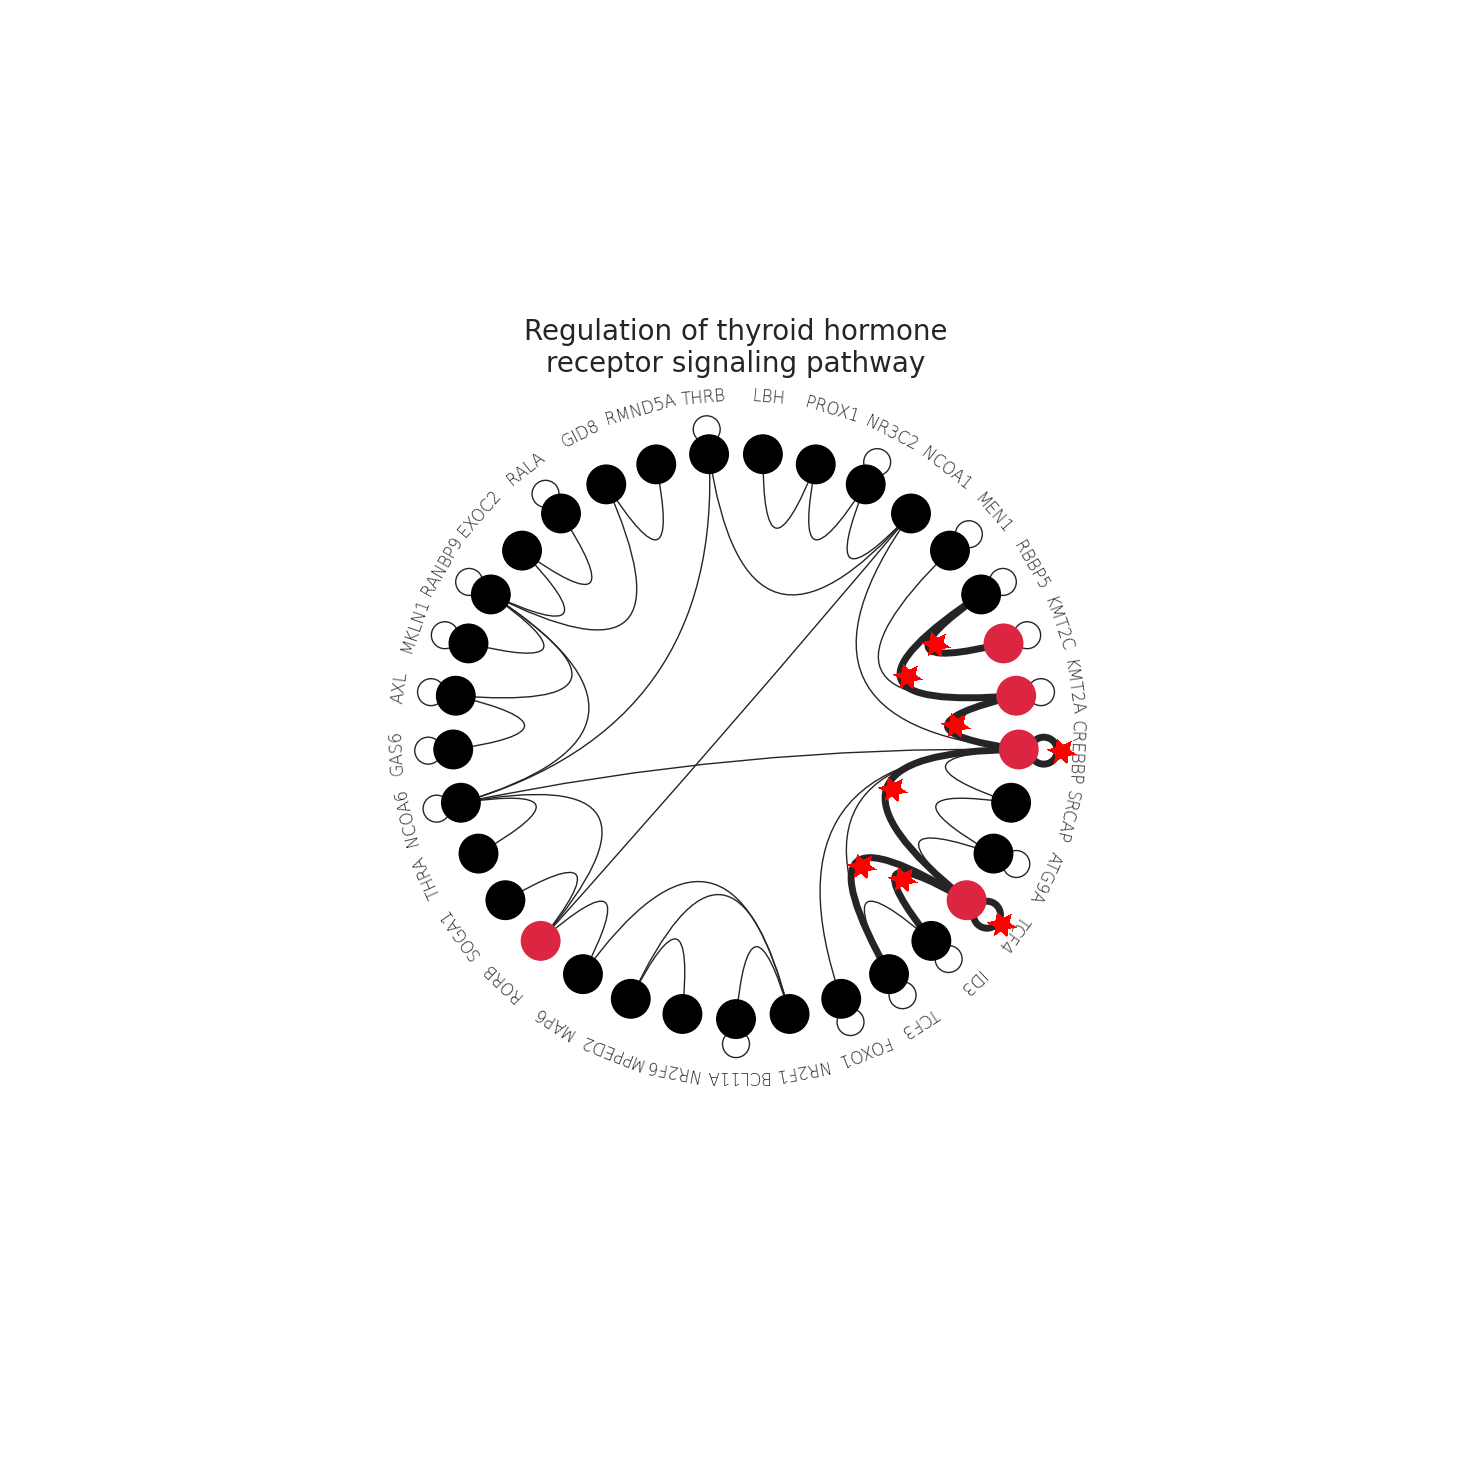

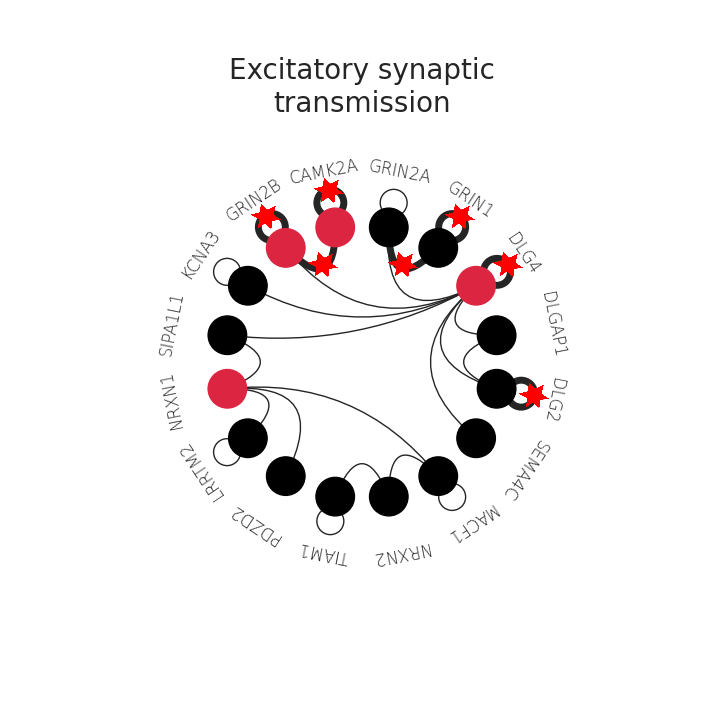

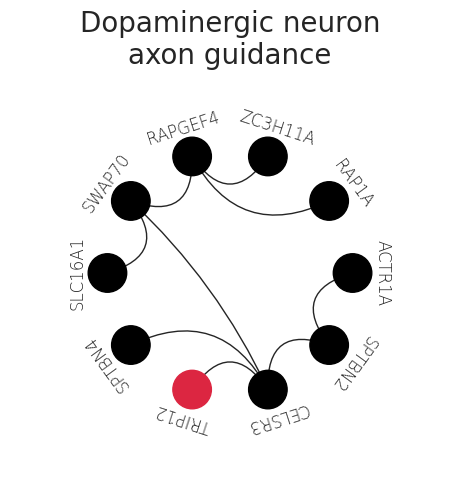

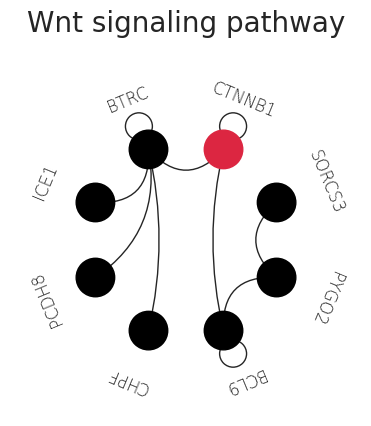

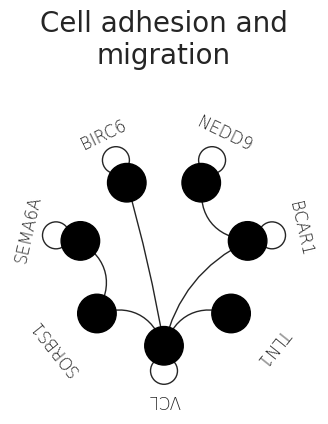

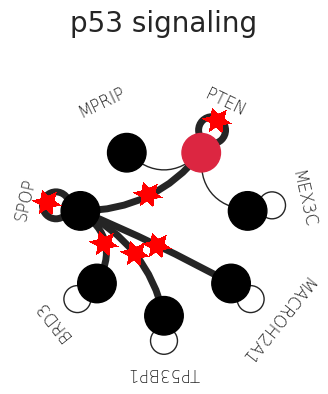

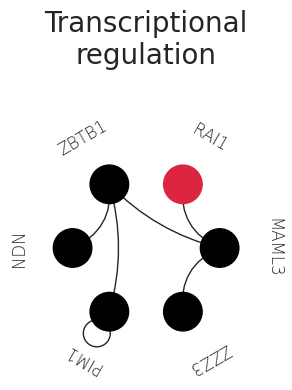

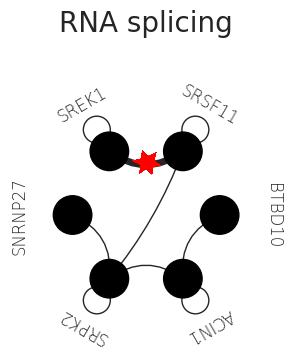

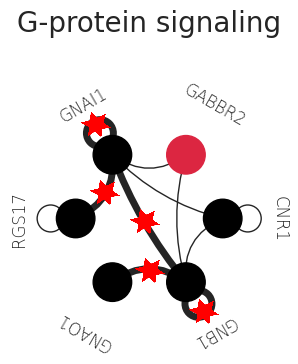

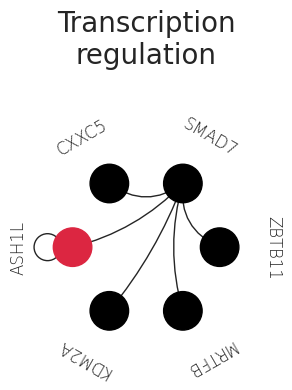

In [62]:
for x in df_sig.iterrows():
    subnetwork_id = x[1]["subnetwork_id"]
    title = module2title[subnetwork_id]
    print(subnetwork_id)
    prots = x[1]["Subnetwork_genes"].split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    b = len(set(G_sub.nodes()))

    figsize = 20 / 35 * len(set(G_sub.nodes()))
    figure, ax = plt.subplots(figsize = (figsize, figsize))
    x_range = (-figsize, figsize)
    y_range = (-figsize, figsize)
    try:
        ordered_genes = module2ordered_genes[subnetwork_id]
    except:
        ordered_genes = list(G_sub.nodes())
    if x[1]["Subnetwork_size"] > 15:
         interval_ratio = 0.4
    else:
        interval_ratio = 1
    shell_layout_ASD(G_sub, cluster_marker, ax, x_range=x_range, y_range = y_range, output = figure_path + title.replace("\n", "_").replace(" ", "_") + "_FuTADA.pdf", ordered_genes = ordered_genes, interval_ratio = interval_ratio, \
        edge_magnifier = 1, fontsize = 12, benchmarkcat2genes = benchmarkcat2genes, benchmarkcat2color = benchmarkcat2color, \
        center = (0,0), marker_zoom = 0.05, title = module2title[subnetwork_id], title_pos = "top", title_fontsize = 20)

## highlight our TADA genes

### parse our TADA genes

In [90]:
# load Fu's TADA genes
dr = f"{folder_path}/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep="\t")
df

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.0,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.0,1.000000,1.000000,1.249983e+07,1.296459e-07,1.980326e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.033308,1.000000e+00,38.567683,1.393818,1.0,4560.822556,1.079713,2.647166e+05,7.895777e-06,1.833227e-08
2,SMC3,SMC3,ENSG00000108055,1.584900e-01,3.195632e-03,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.005344,1.000000e+00,27.577746,1.000000,1.0,1.000000,1.012382,2.791921e+01,1.646678e-01,4.034511e-03
3,CNOT1,CNOT1,ENSG00000125107,5.438422e-01,4.129344e-02,0.000000e+00,0.627486,0.000000,0.0,0.000000,0.000000,1.000000e+00,4.241178,1.000000,1.0,1.000000,1.000000,4.241178e+00,5.474731e-01,5.084453e-02
4,RLF,RLF,ENSG00000117000,6.212839e-01,6.376324e-02,4.636165e-01,0.000000,0.023187,0.0,0.000000,0.084348,2.908148e+00,1.000000,1.054841,1.0,1.000000,1.214362,3.725217e+00,5.761548e-01,5.963352e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,8.833030e-01,5.662839e-01,1.928655e-16,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.873131e-01,7.393219e-01
18124,PSG1,PSG1,ENSG00000231924,9.110422e-01,9.999425e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.906305e-01,7.835519e-01
18125,NBPF10,NBPF10,ENSG00000163386,9.110443e-01,1.000000e+00,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,9.028326e-01,9.997678e-01
18126,LZTR1,LZTR1,ENSG00000099949,7.821813e-01,1.861275e-01,3.525056e-03,0.090901,0.083536,0.0,0.000000,0.000000,1.008150e+00,1.232823,1.212093,1.0,1.000000,1.000000,1.506474e+00,7.856974e-01,2.328758e-01


In [92]:
our_tada_genes = df[df["FDR_TADA_ASD_AddEM"] < 0.05]["gene"].tolist()
print(len(our_tada_genes), our_tada_genes[:10])

211 ['MED13', 'NIPBL', 'NCKAP1', 'XPO1', 'PRR12', 'SYNGAP1', 'HDAC4', 'SMARCA4', 'TRIP12', 'KDM3B']


In [93]:
benchmarkcat2genes = {"Our TADA genes": our_tada_genes}

In [94]:
benchmarkcat2color = {"Our TADA genes": "#dc2641", \
                    }

### draw subnetworks

In [95]:
df_sig

,Subnetwork_genes,Subnetwork_size,subnetwork_id
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",33,size33_1
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",16,size16_1
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10,size10_1
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8,size8_1
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7,size7_1
5,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3,Q6WCQ1",7,size7_2
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6,size6_1
7,"P78362,Q05519,Q8WVK2,Q8WXA9,Q9BSF8,Q9UKV3",6,size6_2
8,"O75899,P09471,P21554,P62873,P63096,Q9UGC6",6,size6_3
9,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6,size6_4


In [96]:
for x in df_sig["Subnetwork_genes"]:
    prots = x.split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    print(G_sub.nodes())

['ID3', 'ATG9A', 'MAP6', 'MEN1', 'PROX1', 'RBBP5', 'BCL11A', 'EXOC2', 'NR3C2', 'NCOA6', 'THRA', 'TCF4', 'NCOA1', 'THRB', 'RANBP9', 'LBH', 'GAS6', 'RMND5A', 'NR2F1', 'TCF3', 'RALA', 'KMT2C', 'RORB', 'GID8', 'CREBBP', 'MKLN1', 'SOGA1', 'FOXO1', 'MPPED2', 'SRCAP', 'AXL', 'NR2F6', 'KMT2A']
['KCNA3', 'GRIN1', 'DLG2', 'DLG4', 'NRXN2', 'SIPA1L1', 'GRIN2B', 'PDZD2', 'CAMK2A', 'SEMA4C', 'MACF1', 'LRRTM2', 'TIAM1', 'NRXN1', 'GRIN2A', 'DLGAP1']
['SLC16A1', 'CELSR3', 'RAPGEF4', 'ZC3H11A', 'SPTBN4', 'SPTBN2', 'TRIP12', 'ACTR1A', 'SWAP70', 'RAP1A']
['CHPF', 'PCDH8', 'PYGO2', 'SORCS3', 'BCL9', 'BTRC', 'ICE1', 'CTNNB1']
['BIRC6', 'SORBS1', 'NEDD9', 'BCAR1', 'TLN1', 'SEMA6A', 'VCL']
['MEX3C', 'SPOP', 'TP53BP1', 'BRD3', 'MPRIP', 'MACROH2A1', 'PTEN']
['PIM1', 'ZBTB1', 'NDN', 'MAML3', 'RAI1', 'ZZZ3']
['SRSF11', 'SRPK2', 'ACIN1', 'SNRNP27', 'SREK1', 'BTBD10']
['GABBR2', 'CNR1', 'GNAO1', 'RGS17', 'GNB1', 'GNAI1']
['MRTFB', 'KDM2A', 'ZBTB11', 'ASH1L', 'SMAD7', 'CXXC5']


In [97]:
module2ordered_genes = {
    "size33_1": ['THRB', 'RMND5A', 'GID8', 'RALA', 'EXOC2', 'RANBP9', 'MKLN1', 'AXL', 'GAS6', 'NCOA6', 'THRA', 'SOGA1', 'RORB', 'MAP6', 'MPPED2', 'NR2F6', 'BCL11A', 'NR2F1', 'FOXO1', 'TCF3', 'ID3', 'TCF4', 'ATG9A', 'SRCAP', 'CREBBP', 'KMT2A', 'KMT2C', 'RBBP5', 'MEN1', 'NCOA1', 'NR3C2', 'PROX1', 'LBH'], 
    "size16_1": ['CAMK2A', 'GRIN2B', 'KCNA3', 'SIPA1L1', 'NRXN1', 'LRRTM2', 'PDZD2', 'TIAM1', 'NRXN2', 'MACF1', 'SEMA4C', 'DLG2', 'DLGAP1', 'DLG4','GRIN1', 'GRIN2A'],
    "size10_1": ['RAPGEF4', 'SWAP70', 'SLC16A1', 'SPTBN4', 'TRIP12', 'CELSR3', 'SPTBN2', 'ACTR1A', 'RAP1A', 'ZC3H11A'],
    "size8_1": ['BTRC', 'ICE1', 'PCDH8', 'CHPF', 'BCL9', 'PYGO2', 'SORCS3', 'CTNNB1'],
    "size7_1": ['BIRC6', 'SEMA6A', 'SORBS1', 'VCL', 'TLN1', 'BCAR1', 'NEDD9'], 
    "size7_2": ['MPRIP', 'SPOP', 'BRD3', 'TP53BP1', 'MACROH2A1', 'MEX3C', 'PTEN'], 
    "size6_1": ['ZBTB1', 'NDN', 'PIM1', 'ZZZ3', 'MAML3', 'RAI1'],
    "size6_2": ['SREK1', 'SNRNP27', 'SRPK2', 'ACIN1', 'BTBD10', 'SRSF11'],
    "size6_3": ['GNAI1', 'RGS17', 'GNAO1', 'GNB1', 'CNR1', 'GABBR2'],
    "size6_4": ['CXXC5', 'ASH1L', 'KDM2A', 'MRTFB', 'ZBTB11', 'SMAD7']
}
module2title = {
    "size33_1": "Regulation of thyroid hormone\nreceptor signaling pathway", 
    "size16_1": "Excitatory synaptic\ntransmission\n", 
    "size10_1": "Dopaminergic neuron\naxon guidance\n", 
    "size8_1": "Wnt signaling pathway\n", 
    "size7_1": "Cell adhesion and\nmigration\n", 
    "size7_2": "p53 signaling\n", 
    "size6_1": "Transcriptional\nregulation\n",
    "size6_2": "RNA splicing\n",
    "size6_3": "G-protein signaling\n",
    "size6_4": "Transcription\nregulation\n",
}

size33_1
size16_1
size10_1
size8_1
size7_1
size7_2
size6_1
size6_2
size6_3
size6_4


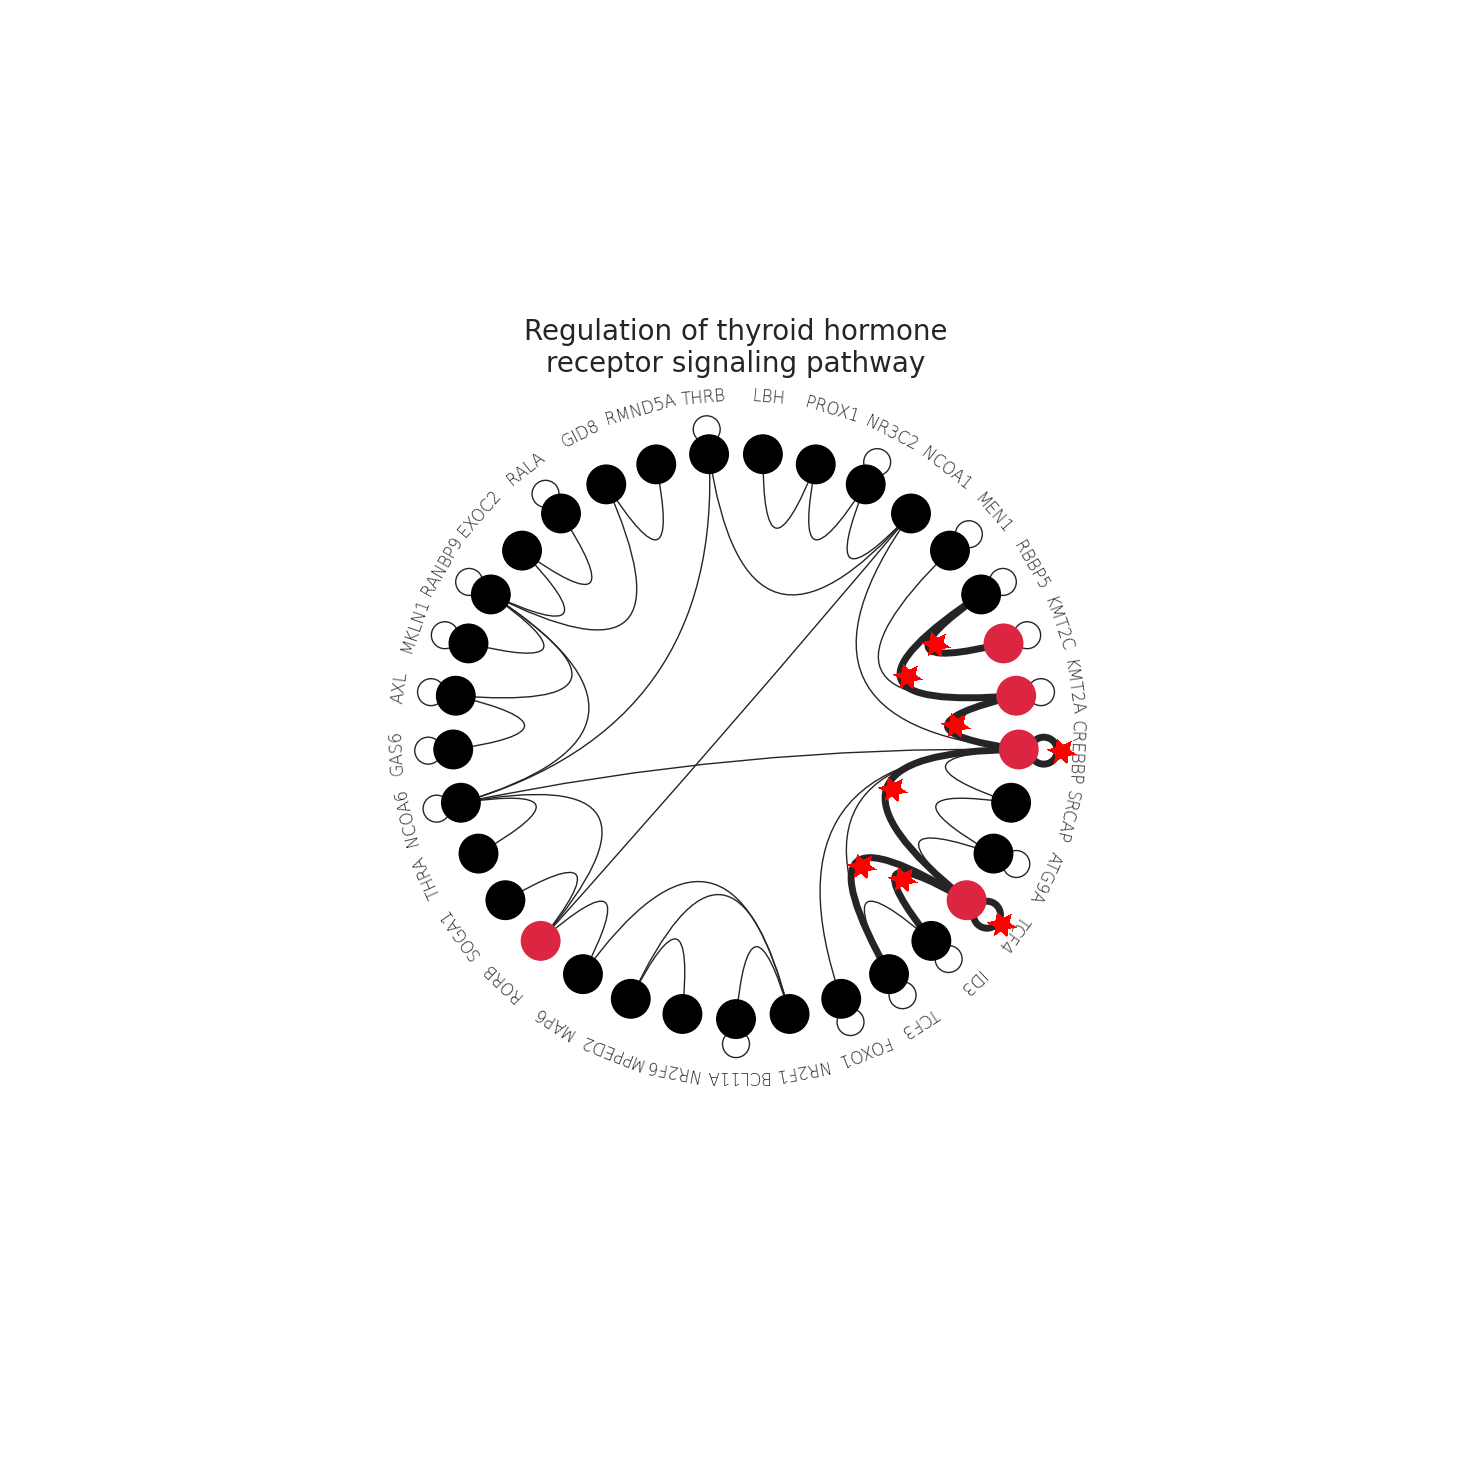

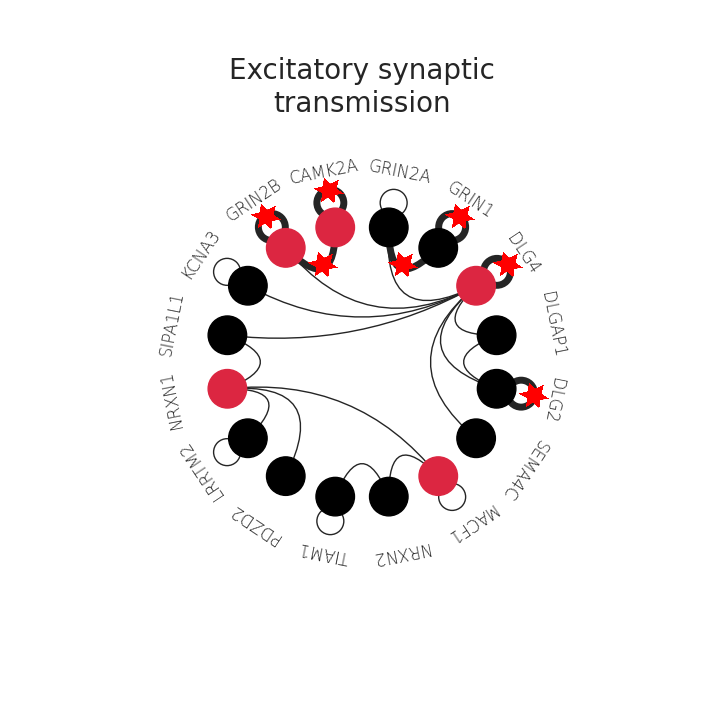

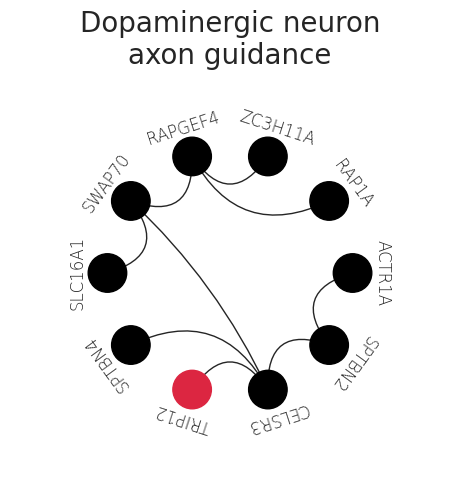

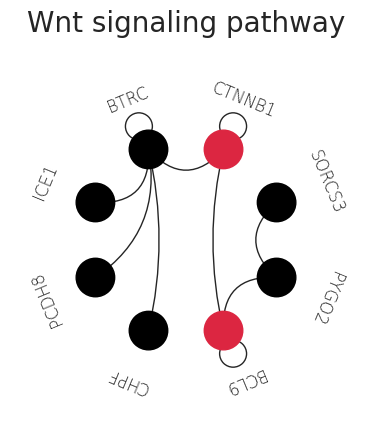

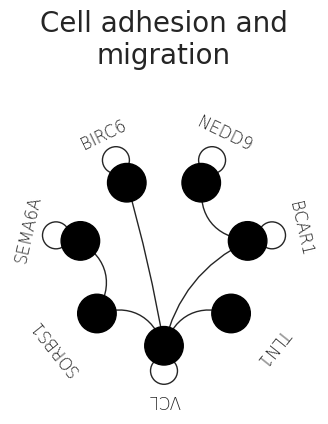

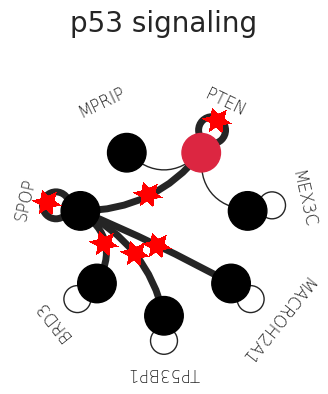

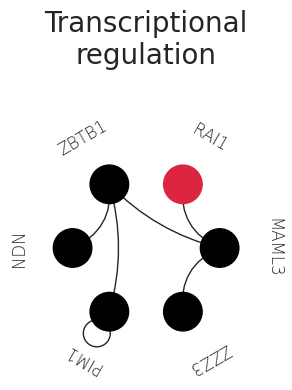

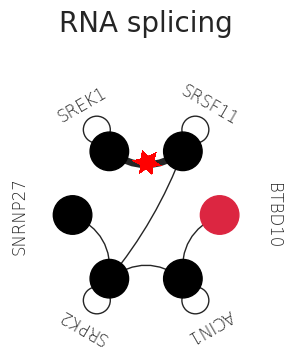

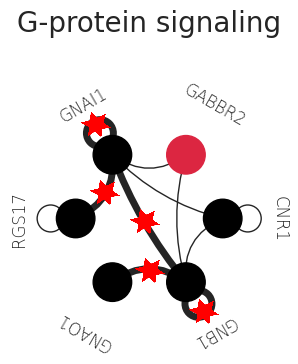

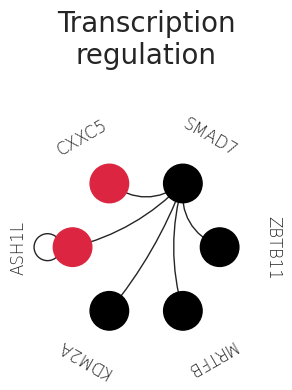

In [98]:
for x in df_sig.iterrows():
    subnetwork_id = x[1]["subnetwork_id"]
    title = module2title[subnetwork_id]
    print(subnetwork_id)
    prots = x[1]["Subnetwork_genes"].split(",")
    G_sub = G.subgraph(prots)
    a = len(set(G_sub.nodes()))
    G_sub = nx.relabel_nodes(G_sub, dict(zip(df_idmap["UniProt"], df_idmap["ID"])))
    b = len(set(G_sub.nodes()))

    figsize = 20 / 35 * len(set(G_sub.nodes()))
    figure, ax = plt.subplots(figsize = (figsize, figsize))
    x_range = (-figsize, figsize)
    y_range = (-figsize, figsize)
    try:
        ordered_genes = module2ordered_genes[subnetwork_id]
    except:
        ordered_genes = list(G_sub.nodes())
    if x[1]["Subnetwork_size"] > 15:
         interval_ratio = 0.4
    else:
        interval_ratio = 1
    shell_layout_ASD(G_sub, cluster_marker, ax, x_range=x_range, y_range = y_range, output = figure_path + title.replace("\n", "_").replace(" ", "_") + "_OurTADA.pdf", ordered_genes = ordered_genes, interval_ratio = interval_ratio, \
        edge_magnifier = 1, fontsize = 12, benchmarkcat2genes = benchmarkcat2genes, benchmarkcat2color = benchmarkcat2color, \
        center = (0,0), marker_zoom = 0.05, title = module2title[subnetwork_id], title_pos = "top", title_fontsize = 20)